# Actuarial Science: Real Open-Source Insurance Data Laboratory

**Companion to the revised standalone book chapter**  
**Observed source:** RAND Health Insurance Experiment (RAND HIE), distributed in `statsmodels.datasets.randhie` (20,190 rows).  
**Actual observed outcome:** outpatient medical-doctor visits (`mdvis`), **not claims or spending**.  
**Illustrative only:** reimbursement per visit, premiums, aggregate payments, stress buffers and settlement schedules.

The experiment's insurance plan characteristics and utilisation data are historically observed, but the flat cost per visit assumed later is neither observed nor a historical/recommended reimbursement. Do **not** describe modelled visits as insurance claims or simulated payments as empirical paid losses. No real-world insurance premium or reserve is identified by these data alone.

**Scientific design:** random train/test split at record level, explicitly **not** a temporal holdout. The public subset contains no participant identifier, so multiple records belonging to one participant cannot be blocked across folds; observed performance may be optimistic. Associations are predictive, not causal effects of cost sharing.

**Source:** https://www.statsmodels.org/v0.14.6/datasets/generated/randhie.html . Source context: RAND HIE (1974–1982). No internet required because the unmodified source observations are bundled in CSV; alternatively, `statsmodels` can load the same data.

## 1. Study design and statistical questions

1. Describe utilisation by insurance and health characteristics. 2. Develop an out-of-sample model of physician-visit counts. 3. Compare a transparent pooled-rate benchmark and Poisson GLM. 4. Assess zero inflation, overdispersion and subgroup calibration. 5. Convert the *predicted visits* into expressly **assumed** reimbursement scenarios and show how the actuarial premium calculation would work if reliable medical unit costs existed. 6. Simulate aggregate scenario payments and distinguish demonstration-based buffers from regulatory capital and authentic actuarial reserves.

**Interpretation warning:** this is historical United States health-insurance evidence, not a contemporary international insurance pricing dataset. Monetary amounts are *illustrative 2026 exercise units labelled USD* and are not adjusted RAND HIE historical dollars.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance
SEED=20261119
rng=np.random.default_rng(SEED)
path=Path('rand_hie_open_source_observations.csv')
if not path.exists():
    import statsmodels.api as sm
    data=sm.datasets.randhie.load_pandas().data.copy()
else:
    data=pd.read_csv(path)
print('Source rows / columns:', data.shape)
print(data.head(3).to_string(index=False))

Source rows / columns: (20190, 10)
 mdvis  lncoins  idp      lpi  fmde  physlm    disea  hlthg  hlthf  hlthp
     0  4.61512    1 6.907755   0.0     0.0 13.73189      1      0      0
     2  4.61512    1 6.907755   0.0     0.0 13.73189      1      0      0
     0  4.61512    1 6.907755   0.0     0.0 13.73189      1      0      0


## 2. Data dictionary, audit and exposure boundaries

- `mdvis`: number of outpatient medical-doctor visits (response, not claim count).
- `lncoins`: log(coinsurance + 1); `idp`: indicator for individual deductible plan; `lpi`: logged participation incentive; `fmde`: transformed medical deductible expenditure-related measure.
- `physlm`: physical limitation indicator; `disea`: chronic-disease measure; `hlthg`, `hlthf`, `hlthp`: self-rated health indicators (reference: excellent).

The dataset **does not include the observed amount of each visit**, claim-level payment or explicit exposure duration. Thus this exercise treats each record as one *comparable observational unit*, not as a known policy-year. Annualisation is **not inferred**; the model predicts visits *per dataset record*. Avoid calling the output an annual actuarial rate without verifying documentation.

In [2]:
assert len(data)==20190
assert list(data.columns)==['mdvis','lncoins','idp','lpi','fmde','physlm','disea','hlthg','hlthf','hlthp']
assert data.notna().all().all()
assert data.mdvis.ge(0).all()
print('Missing values:',int(data.isna().sum().sum()))
print('Zero visits:',int(data.mdvis.eq(0).sum()),'or',round(data.mdvis.eq(0).mean()*100,1),'%')
print('Observed mean:',round(data.mdvis.mean(),3),'variance:',round(data.mdvis.var(),3),'max:',int(data.mdvis.max()))
assert data.mdvis.var()>data.mdvis.mean(), 'Expected overdispersion for this worked example.'

Missing values: 0
Zero visits: 6308 or 31.2 %
Observed mean: 2.86 variance: 20.289 max: 77


## 3. Descriptive statistics
Mean and variance measure central tendency and dispersion; overdispersion and a high zero share are reasons to examine Poisson assumptions critically, **not** proof of a specific alternative distribution.

     observations  mean_visits  zero_share  variance
idp                                                 
0           14941        2.996       0.291    21.327
1            5249        2.473       0.372    17.136


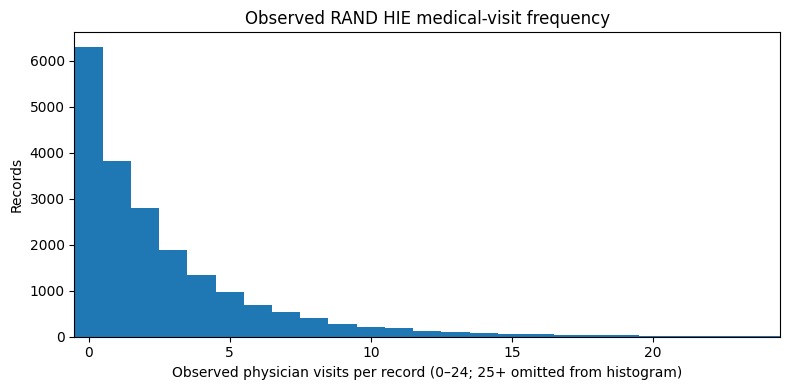

In [3]:
table=data.groupby('idp').agg(observations=('mdvis','size'),mean_visits=('mdvis','mean'),zero_share=('mdvis',lambda x:(x==0).mean()),variance=('mdvis','var'))
print(table.round(3).to_string())
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(data.mdvis,bins=np.arange(0,26)-.5)
ax.set(xlabel='Observed physician visits per record (0–24; 25+ omitted from histogram)',ylabel='Records',title='Observed RAND HIE medical-visit frequency')
ax.set_xlim(-.5,24.5);plt.tight_layout();plt.show()

## 4. Reproducible record-level holdout and baseline

Use a fixed-seed 75/25 random record split. No calendar field or persistent person ID is provided; therefore this is **not** temporal or person-independent validation. Fit only the development sample, then score the untouched test records. The pooled baseline predicts the mean development count for every record.

In [4]:
features=[x for x in data.columns if x!='mdvis']
train_idx,test_idx=train_test_split(np.arange(len(data)),test_size=.25,random_state=SEED)
train=data.iloc[train_idx].copy();test=data.iloc[test_idx].copy()
base_mu=np.repeat(train.mdvis.mean(),len(test))
print('Development:',len(train),'Test:',len(test),'development mean:',round(train.mdvis.mean(),3))

Development: 15142 Test: 5048 development mean: 2.848


## 5. Poisson GLM: a transparent statistical baseline
The Poisson response assumption states E[Y|X]=Var[Y|X] and uses a log link. Fit a regularised Poisson regression with standardised predictors to avoid numerical instability. The method may be misspecified for these overdispersed counts; its value is as a transparent benchmark.

In [5]:
model=Pipeline([('scale',StandardScaler()),('poisson',PoissonRegressor(alpha=.1,max_iter=700))])
model.fit(train[features],train.mdvis)
mu=np.maximum(model.predict(test[features]),1e-8)
metrics=pd.DataFrame([
 {'model':'pooled mean','mae':mean_absolute_error(test.mdvis,base_mu),'poisson_deviance':mean_poisson_deviance(test.mdvis,base_mu),'pred_total':sum(base_mu)},
 {'model':'Poisson GLM','mae':mean_absolute_error(test.mdvis,mu),'poisson_deviance':mean_poisson_deviance(test.mdvis,mu),'pred_total':sum(mu)}])
print(metrics.round(3).to_string(index=False)); print('Observed holdout visits:',int(test.mdvis.sum()))

      model   mae  poisson_deviance  pred_total
pooled mean 2.749             4.633   14376.565
Poisson GLM 2.600             4.177   14461.523
Observed holdout visits: 14628


## 6. Calibration and dispersion diagnostics

Pooled predictions may match overall volume yet fail across health-status or insurance groups. Subgroup table compares predicted and observed *visits per record*, not event probabilities. Pearson dispersion uses residual variance relative to fitted conditional means and remains descriptive rather than a formal person-cluster-adjusted diagnostic.

        n  actual_mean  predicted_mean  ratio_actual_to_pred
idp                                                         
0    3750        3.042           2.991                 1.017
1    1298        2.480           2.499                 0.992
Approx. holdout Pearson dispersion: 6.393


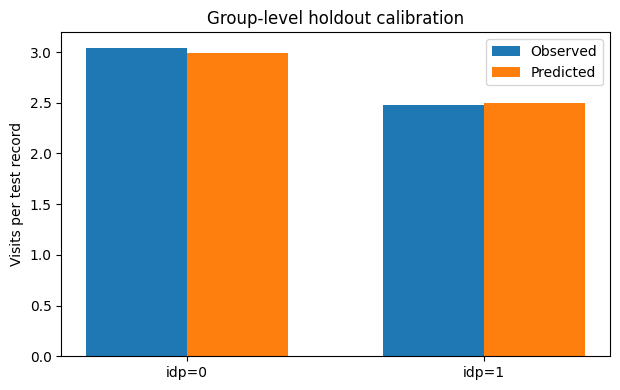

In [6]:
scored=test.copy();scored['pred_visits']=mu
cal=scored.groupby('idp').agg(n=('mdvis','size'),actual_mean=('mdvis','mean'),predicted_mean=('pred_visits','mean'))
cal['ratio_actual_to_pred']=cal.actual_mean/cal.predicted_mean
print(cal.round(3).to_string())
pearson=np.sum((scored.mdvis-scored.pred_visits)**2/np.maximum(scored.pred_visits,1e-8))/(len(scored)-len(features)-1)
print('Approx. holdout Pearson dispersion:',round(pearson,3))
fig,ax=plt.subplots(figsize=(6.3,4));idx=np.arange(len(cal));ax.bar(idx-.17,cal.actual_mean,width=.34,label='Observed');ax.bar(idx+.17,cal.predicted_mean,width=.34,label='Predicted');ax.set_xticks(idx,['idp=0','idp=1']);ax.set(ylabel='Visits per test record',title='Group-level holdout calibration');ax.legend();plt.tight_layout();plt.show()

## 7. Illustrative frequency × assumed unit cost (NOT fitted claim severity)

A classical frequency–severity premium is expected count × expected *paid* cost per occurrence. Since claim payments are unavailable, assume a **flat hypothetical reimbursement of $150 per visit**, used purely for teaching. It is not an estimated severity, not a fact about RAND HIE medical spending, and not a recommended premium. The numerical result is **per observational record**, not per policy-year.

Assumed gross-price formula: `scenario payment / (1 - expense_ratio - margin)` where the ratios are also hypothetical. Expenses, inflation, plan limits, covered services, provider networks and payer-paid amounts would have to be measured for genuine pricing.

In [7]:
ASSUMED_USD_PER_VISIT=150.0;EXPENSE_RATIO=.25;TARGET_MARGIN=.05
scenario_expected_payments=mu.sum()*ASSUMED_USD_PER_VISIT
pure_cost_per_record=scenario_expected_payments/len(test)
scenario_gross_per_record=pure_cost_per_record/(1-EXPENSE_RATIO-TARGET_MARGIN)
print(f'Hypothetical expected payment per test record: ${pure_cost_per_record:,.2f}')
print(f'Hypothetical gross price per test record: ${scenario_gross_per_record:,.2f}')
print(f'Hypothetical aggregate payments for test group: ${scenario_expected_payments:,.2f}')

Hypothetical expected payment per test record: $429.72
Hypothetical gross price per test record: $613.89
Hypothetical aggregate payments for test group: $2,169,228.39


## 8. Simulation: explicit uncertainty assumptions

The data show overdispersion, so an **illustrative** negative-binomial aggregate visit-count assumption is used. We calibrate a simple dispersion factor from the development sample with moments, making no claim of a fully fitted longitudinal insurance model. Event payments are assumed identical ($150) in the main simulation. This ignores severity variation and correlations across individuals, so its tail estimates must *not* be used for statutory insurance capital. Simulation only gives a conditional scenario range under its specified assumptions.

Illustrative NB dispersion shape per record: 0.468
Scenario mean USD     2169443.66
Scenario P95 USD      2250450.00
Scenario P99 USD      2286319.50
P99-minus-mean USD     116875.84


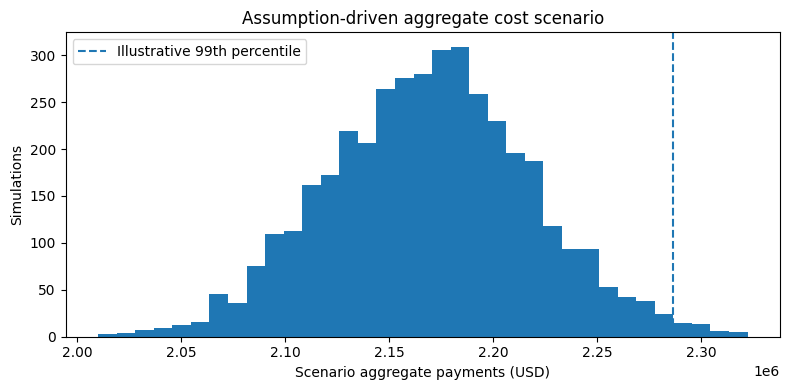

In [8]:
n_sims=4000
train_mean=train.mdvis.mean(); train_var=train.mdvis.var()
nb_k=max(0.1,train_mean**2/max(train_var-train_mean,1e-8))
# Approximate a portfolio-level NB total to avoid allocating simulation arrays of size n_sims x n_records.
# Independent Gamma-mixed Poisson individuals imply NB total with shape=sum(k_i) and mean=sum(mu_i).
# Here k_i=nb_k, so aggregation uses shape=len(test)*nb_k and fitted total mean.
shape=len(test)*nb_k; total_mu=mu.sum(); probability=shape/(shape+total_mu)
counts=rng.negative_binomial(shape,probability,size=n_sims)
losses=counts*ASSUMED_USD_PER_VISIT
print('Illustrative NB dispersion shape per record:',round(nb_k,3))
print(pd.Series({'Scenario mean USD':np.mean(losses),'Scenario P95 USD':np.quantile(losses,.95),'Scenario P99 USD':np.quantile(losses,.99),'P99-minus-mean USD':np.quantile(losses,.99)-np.mean(losses)}).round(2).to_string())
fig,ax=plt.subplots(figsize=(8,4));ax.hist(losses,bins=35);ax.axvline(np.quantile(losses,.99),linestyle='--',label='Illustrative 99th percentile');ax.set(xlabel='Scenario aggregate payments (USD)',ylabel='Simulations',title='Assumption-driven aggregate cost scenario');ax.legend();plt.tight_layout();plt.show()

## 9. Stress testing and unit-cost uncertainty
Stress independently the predicted utilisation, assumed reimbursement and expense loading. These are scenario choices and should not be interpreted as inferred inflation, disease trends or published actuarial loadings.

In [9]:
stresses=pd.DataFrame([('Base assumption',1,1),('Visits +20%',1.2,1),('Unit cost +25%',1,1.25),('Joint adverse',1.2,1.25)],columns=['scenario','visit_multiplier','unit_cost_multiplier'])
stresses['scenario_total_usd']=total_mu*ASSUMED_USD_PER_VISIT*stresses.visit_multiplier*stresses.unit_cost_multiplier
stresses['relative_to_base_pct']=(stresses.scenario_total_usd/scenario_expected_payments-1)*100
print(stresses.round(2).to_string(index=False))

       scenario  visit_multiplier  unit_cost_multiplier  scenario_total_usd  relative_to_base_pct
Base assumption               1.0                  1.00          2169228.39                   0.0
    Visits +20%               1.2                  1.00          2603074.07                  20.0
 Unit cost +25%               1.0                  1.25          2711535.49                  25.0
  Joint adverse               1.2                  1.25          3253842.58                  50.0


## 10. Discounting and the difference between a teaching example and reserves
A claim reserve concerns *incurred obligations*, including unpaid claims and development uncertainty. The RAND subset contains neither incurred claims nor settlement dates. The code here merely discounts **hypothetical future scenario payments**, using an assumed 70%/30% payment schedule at years 1 and 2 and an assumed 3.5% annual rate; this is **not** a booked reserve or IBNR estimate.

In [10]:
schedule={1:.7,2:.3};discount_rate=.035
pv=sum(scenario_expected_payments*p/(1+discount_rate)**t for t,p in schedule.items())
print(f'Illustrative future nominal cash flows: ${scenario_expected_payments:,.2f}')
print(f'Illustrative present value (not a reserve): ${pv:,.2f}')

Illustrative future nominal cash flows: $2,169,228.39
Illustrative present value (not a reserve): $2,074,610.36


## 11. Conclusions and responsible use

- **Observed:** physician visit counts, group covariates, dispersion, holdout error, group calibration.
- **Estimated from observed data:** Poisson GLM expected visits per record (with random-row validation limitations).
- **Assumed rather than observed:** cost per visit, gross price, loss distributions, severity variation, stress multipliers, interest and payout schedule.
- **Not supported:** validated claims severity, paid insurance premiums, actual claims reserves, contemporary pricing, causal effects or regulatory capital.

For a genuine frequency–severity insurance exercise, use a dataset with policy exposure, observed claim counts, linked **paid claim amounts**, valuation dates and claim development. The open French motor third-party liability `freMTPL2freq`/`freMTPL2sev` datasets are appropriate candidates, but were not used for this execution.

## Source and reproducibility
`statsmodels` RAND HIE: https://www.statsmodels.org/v0.14.6/datasets/generated/randhie.html
RAND study documentation: https://www.icpsr.umich.edu/web/NACDA/studies/6439
Run locally with the bundled CSV and `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `nbformat`, `nbclient`. Check `requirements.txt`.